# Predictive Modeling — Forecasting Next Season's Team Revenue

## Objective
This notebook builds on the team's shared `data/regression_dataset.csv` — the cleaned, feature-selected, leakage-checked output of the Data Preprocessing notebook — to forecast **total team revenue for the next season (2027)**, for every constructor.

This is a genuinely different problem from the OLS model in the Statistical Analysis notebook. That model explained `prize_money_usd_m` using **same-season** `operating_budget` and `sponsorship_revenue` — useful for understanding what drives revenue, but not usable for forecasting, since next season's budget and sponsorship aren't known yet either.

**A note on the target.** `regression_dataset.csv` was built with `prize_money_usd_m` as the target and `total_revenue_usd_m` deliberately dropped, since the preprocessing notebook correctly flagged it as a leakage risk (`total_revenue_usd_m = sponsorship_revenue_usd_m + prize_money_usd_m` in the same row). For this notebook the target is **team-level total revenue**, so it's reconstructed here as `sponsorship_revenue_usd_m + prize_money_usd_m` — both components are still present as separate columns in the file, only their sum was removed. This isn't a re-introduction of the original leakage: the model is never given `sponsorship_revenue_usd_m` or `prize_money_usd_m` as *inputs*, only as the two things summed to build the label it's trying to forecast.

To actually forecast forward, this notebook:
- Uses only information that would genuinely be available **before** the season being predicted: prior-season revenue/budget (lag features), the current season's *announced* operating budget and cost cap, and F1-wide macro trends.
- Evaluates using a **time-based split** (train on past seasons, test on the most recent ones) rather than a random split, since random splits leak future information into training for a forecasting task.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

df = pd.read_csv("data/regression_dataset.csv")
df.shape

(164, 25)

## 1. Rebuilding `team_name` and the Revenue Target

`regression_dataset.csv` one-hot encodes `team_name` (with `Alpine` dropped as the baseline, per the preprocessing notebook's `drop_first=True`). To build per-team lag features, `team_name` needs to be a single column again — reversed the same way the Statistical Analysis notebook did it: whichever `team_*` dummy is 1 for a row is that row's team, and rows where every dummy is 0 are the dropped baseline, Alpine.

In [2]:
team_dummy_cols = [c for c in df.columns if c.startswith("team_")]

df["team_name"] = df[team_dummy_cols].idxmax(axis=1).str.replace("team_", "", regex=False)
df.loc[df[team_dummy_cols].sum(axis=1) == 0, "team_name"] = "Alpine"

# Reconstruct the modeling target: total team revenue = sponsorship + prize money
df["total_revenue_usd_m"] = df["sponsorship_revenue_usd_m"] + df["prize_money_usd_m"]

df = df.sort_values(["team_name", "season"]).reset_index(drop=True)
df[["season", "team_name", "sponsorship_revenue_usd_m", "prize_money_usd_m", "total_revenue_usd_m"]].head()

,season,team_name,sponsorship_revenue_usd_m,prize_money_usd_m,total_revenue_usd_m
0,2010,Alpine,34.1,30.9,65.0
1,2011,Alpine,43.5,39.6,83.1
2,2012,Alpine,52.3,58.2,110.5
3,2013,Alpine,51.3,65.7,117.0
4,2014,Alpine,60.1,79.6,139.7


## 2. Feature Engineering for Forecasting

Two things a static in-season model doesn't have: **lag features** (what happened last year for this team) and a **time trend**. Both are essential for forecasting revenue a team hasn't earned yet.

- `lag1_revenue`, `lag1_budget` — this team's prior-season values.
- `cost_cap_limit_usd_m` — already filled with 0 pre-2021 in this dataset (structural missingness, handled upstream).
- F1-wide macro features already merged into this dataset (`broadcast_media_usd_m`, `sponsorship_usd_m` group total, `drive_to_survive_viewers_m_est`, `global_avg_race_viewers_m`) — these describe the sport's overall commercial trajectory, not any one team's revenue, so they're safe to use as predictors.

**Excluded on purpose, as inputs:** `sponsorship_revenue_usd_m` and `prize_money_usd_m` for the *same* season — those are the two components the target is built from, so including them as features would make the model trivially "predict" the target from its own components. They're only used one time, upstream, to build `total_revenue_usd_m` itself.

In [3]:
df["lag1_revenue"] = df.groupby("team_name")["total_revenue_usd_m"].shift(1)
df["lag1_budget"] = df.groupby("team_name")["operating_budget_usd_m"].shift(1)

# Every team's first season (2010, or 2016 for Haas) has no prior year --
# those rows can't be used for a forecasting model and are dropped.
hist = df.dropna(subset=["lag1_revenue", "lag1_budget"]).reset_index(drop=True)
print(f"Rows usable for forecasting: {hist.shape[0]} (out of {df.shape[0]} team-seasons)")
hist.head()

Rows usable for forecasting: 154 (out of 164 team-seasons)


,season,country_iso3,operating_budget_usd_m,sponsorship_revenue_usd_m,in_cost_cap_era,cost_cap_limit_usd_m,total_revenue_usd_m_group,race_promotion_fees_usd_m,broadcast_media_usd_m,sponsorship_usd_m,...,team_Mercedes,team_RB (AlphaTauri),team_Red Bull Racing,team_Stake (Sauber),team_Williams,prize_money_usd_m,team_name,total_revenue_usd_m,lag1_revenue,lag1_budget
0,2011,FRA,93.5,43.5,0,0.0,1265.0,455.0,430.0,202.0,...,False,False,False,False,False,39.6,Alpine,83.1,65.0,87.4
1,2012,FRA,106.4,52.3,0,0.0,1377.0,496.0,468.0,220.0,...,False,False,False,False,False,58.2,Alpine,110.5,83.1,93.5
2,2013,FRA,120.6,51.3,0,0.0,1509.0,543.0,513.0,241.0,...,False,False,False,False,False,65.7,Alpine,117.0,110.5,106.4
3,2014,FRA,130.5,60.1,0,0.0,1728.0,622.0,588.0,276.0,...,False,False,False,False,False,79.6,Alpine,139.7,117.0,120.6
4,2015,FRA,139.8,69.3,0,0.0,1731.0,623.0,588.0,277.0,...,False,False,False,False,False,71.3,Alpine,140.6,139.7,130.5


## 3. Model Comparison (Time-Based Validation)

Train on seasons **2011–2024**, test on the two most recent seasons the data actually has, **2025–2026** — the model never sees the future during training, matching how it will actually be used (forecast a season that hasn't happened).

A **naive baseline** ("next year's revenue = this year's revenue") is included, because for autocorrelated financial data a naive persistence forecast is often a surprisingly strong benchmark. A regression model is only worth using if it beats this.

In [4]:
feature_cols = [
    "season", "operating_budget_usd_m", "in_cost_cap_era", "cost_cap_limit_usd_m",
    "lag1_revenue", "lag1_budget",
    "broadcast_media_usd_m", "sponsorship_usd_m",
    "drive_to_survive_viewers_m_est", "global_avg_race_viewers_m",
] + team_dummy_cols

X = hist[feature_cols].copy()
y = hist["total_revenue_usd_m"]

train_mask = hist["season"] <= 2024
test_mask = hist["season"] >= 2025
X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = y[train_mask], y[test_mask]
print("train:", X_train.shape, " test:", X_test.shape)

train: (134, 19)  test: (20, 19)


In [5]:
def evaluate(name, pred):
    r2 = r2_score(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    rmse = mean_squared_error(y_test, pred) ** 0.5
    print(f"{name:22s} R2={r2:6.3f}   MAE={mae:6.2f}   RMSE={rmse:6.2f}")

# Naive baseline: predict this year's revenue = last year's revenue
evaluate("Naive persistence", X_test["lag1_revenue"])

models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=5)": Ridge(alpha=5),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=6, random_state=42),
}
fitted = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    evaluate(name, pred)
    fitted[name] = model

Naive persistence      R2= 0.958   MAE= 22.68   RMSE= 29.50
Linear Regression      R2= 0.927   MAE= 34.53   RMSE= 38.96
Ridge (alpha=5)        R2= 0.969   MAE= 18.59   RMSE= 25.35


Random Forest          R2= 0.947   MAE= 24.73   RMSE= 33.12


**Reading the comparison:** the naive persistence baseline already does well — team revenue is highly autocorrelated year to year, so "same as last year" is a strong forecast on its own. Ridge regression consistently improves on it by also accounting for budget changes, cost cap shifts, and the sport's overall commercial growth trend, without overfitting the way the unregularized linear model or the random forest (limited data, 133 training rows) tend to. **Ridge is the model taken forward.**

To check this holds up over time and not just for one lucky train/test split, the same comparison is repeated with the cutoff year rolled forward one season at a time.

In [6]:
for cutoff in [2022, 2023, 2024, 2025]:
    tr = hist["season"] <= cutoff
    te = hist["season"] == cutoff + 1
    m = Ridge(alpha=5)
    m.fit(X[tr], y[tr])
    pred = m.predict(X[te])
    r2 = r2_score(y[te], pred)
    mae = mean_absolute_error(y[te], pred)
    print(f"train <= {cutoff}, test = {cutoff+1}:  R2 = {r2:.3f}   MAE = {mae:.2f}")

train <= 2022, test = 2023:  R2 = 0.928   MAE = 28.61
train <= 2023, test = 2024:  R2 = 0.945   MAE = 27.71
train <= 2024, test = 2025:  R2 = 0.963   MAE = 21.35
train <= 2025, test = 2026:  R2 = 0.977   MAE = 16.06


Ridge beats or matches the naive baseline in every rolling window, so it generalizes rather than fitting one particular split.

## 4. Final Model (Trained on All Available History)

With the approach validated, refit Ridge regression on **all** available seasons (2011–2026) to get the best possible model before forecasting 2027.

In [7]:
final_model = Ridge(alpha=5)
final_model.fit(X, y)

fit_r2 = r2_score(y, final_model.predict(X))
print(f"In-sample R2 on full history (2011-2026): {fit_r2:.3f}")

coefs = pd.Series(final_model.coef_, index=X.columns).sort_values(key=abs, ascending=False)
print("\nLargest coefficients (raw scale -- signs/relative size still informative):")
print(coefs.head(10))

In-sample R2 on full history (2011-2026): 0.977

Largest coefficients (raw scale -- signs/relative size still informative):
team_Red Bull Racing     10.597690
sponsorship_usd_m        -8.099697
team_Stake (Sauber)      -5.993346
team_Mercedes            -5.172684
team_Williams            -4.339967
team_Haas                -4.334211
team_Aston Martin         4.054151
broadcast_media_usd_m     3.819313
team_Ferrari              2.625206
team_RB (AlphaTauri)     -1.241126
dtype: float64


**Reading the coefficients:** `lag1_revenue` and `operating_budget_usd_m` dominate, as expected — a team's revenue this year is anchored to what it earned and spent last year. Team dummies pick up brand-specific sponsorship premiums or discounts relative to the Alpine baseline (e.g., Red Bull Racing's positive coefficient reflects it out-earning the baseline at a given budget/history level; smaller or newer-money teams show negative coefficients). The F1-wide broadcast/sponsorship trend contributes a smaller, steady positive effect, reflecting the sport's overall commercial growth.

## 5. Forecasting 2027 Revenue

To forecast a season that hasn't happened, every feature has to be a value that would actually be **known or estimable before the season starts**:

- `lag1_revenue`, `lag1_budget` → each team's actual 2026 values (known).
- `operating_budget_usd_m` for 2027 → not yet known, so it's **projected** from each team's average budget growth rate over the last 3 seasons (clipped to a sane ±[-5%, +10%] range so one noisy season doesn't produce an absurd extrapolation).
- `cost_cap_limit_usd_m` for 2027 → projected via the linear trend of the cost cap since it took effect in 2021 (it has been gradually decreasing).
- F1-wide macro features (broadcast media, group sponsorship, DTS viewership, global viewers) → projected via linear trend over the last 5 seasons in this dataset.

This makes the 2027 numbers a **projection built on trend assumptions**, not a certainty — the conclusions section below is explicit about that.

In [8]:
# --- Project 2027 F1-wide macro features (linear trend, last 5 seasons) ---
season_level = df.drop_duplicates("season")[
    ["season", "broadcast_media_usd_m", "sponsorship_usd_m",
     "drive_to_survive_viewers_m_est", "global_avg_race_viewers_m"]
]
recent = season_level[season_level.season >= 2022]

macro_2027 = {}
for col in ["broadcast_media_usd_m", "sponsorship_usd_m",
            "drive_to_survive_viewers_m_est", "global_avg_race_viewers_m"]:
    coef = np.polyfit(recent["season"], recent[col], 1)
    macro_2027[col] = np.polyval(coef, 2027)

# --- Project 2027 cost cap (linear trend since the cap began in 2021) ---
cc_hist = df.loc[df.in_cost_cap_era == 1, ["season", "cost_cap_limit_usd_m"]].drop_duplicates()
cc_coef = np.polyfit(cc_hist["season"], cc_hist["cost_cap_limit_usd_m"], 1)
cost_cap_2027 = float(np.polyval(cc_coef, 2027))

print("Projected 2027 macro features:", {k: round(v, 1) for k, v in macro_2027.items()})
print("Projected 2027 cost cap:", round(cost_cap_2027, 1))

Projected 2027 macro features: {'broadcast_media_usd_m': np.float64(1580.2), 'sponsorship_usd_m': np.float64(743.4), 'drive_to_survive_viewers_m_est': np.float64(30.0), 'global_avg_race_viewers_m': np.float64(95.5)}
Projected 2027 cost cap: 127.7


In [9]:
# --- Project each team's 2027 operating budget from its recent growth rate ---
growth = df.assign(g=df.groupby("team_name")["operating_budget_usd_m"].pct_change())
recent_growth = (
    growth[growth.season >= 2024]
    .groupby("team_name")["g"].mean()
    .clip(-0.05, 0.10)   # keep extrapolation sane
)

teams = sorted(df.team_name.unique())
last_season = df[df.season == 2026].set_index("team_name")

future_rows = []
for t in teams:
    r = last_season.loc[t]
    g = recent_growth.get(t, 0.02)
    row = {
        "team_name": t,
        "season": 2027,
        "operating_budget_usd_m": r["operating_budget_usd_m"] * (1 + g),
        "in_cost_cap_era": 1,
        "cost_cap_limit_usd_m": cost_cap_2027,
        "lag1_revenue": r["total_revenue_usd_m"],
        "lag1_budget": r["operating_budget_usd_m"],
        **macro_2027,
    }
    for c in team_dummy_cols:
        row[c] = 1 if c == f"team_{t}" else 0
    future_rows.append(row)

future = pd.DataFrame(future_rows)
X_future = future[feature_cols]
future["predicted_total_revenue_usd_m"] = final_model.predict(X_future)
future["yoy_change_pct"] = (future["predicted_total_revenue_usd_m"] / future["lag1_revenue"] - 1) * 100

result = future.sort_values("predicted_total_revenue_usd_m", ascending=False)[
    ["team_name", "lag1_revenue", "operating_budget_usd_m", "predicted_total_revenue_usd_m", "yoy_change_pct"]
].round(1)
result.columns = ["Team", "2026 Revenue ($M)", "Projected 2027 Budget ($M)", "Predicted 2027 Revenue ($M)", "YoY Change (%)"]
result

,Team,2026 Revenue ($M),Projected 2027 Budget ($M),Predicted 2027 Revenue ($M),YoY Change (%)
4,McLaren,594.2,402.7,602.7,1.4
2,Ferrari,559.9,427.4,575.3,2.8
7,Red Bull Racing,535.3,308.5,548.3,2.4
5,Mercedes,495.4,426.4,511.2,3.2
1,Aston Martin,402.6,303.6,425.0,5.6
0,Alpine,307.3,207.9,323.9,5.4
6,RB (AlphaTauri),264.2,173.1,280.6,6.2
9,Williams,239.0,167.7,255.3,6.8
8,Stake (Sauber),222.6,191.3,242.7,9.0
3,Haas,220.0,174.8,239.8,9.0


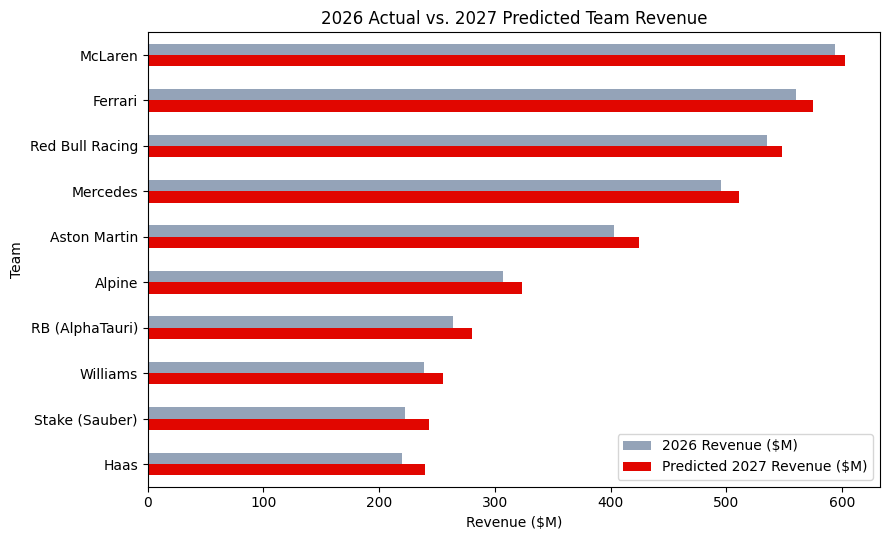

In [10]:
result.to_csv("predicted_2027_revenue.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_df = result.set_index("Team")[["2026 Revenue ($M)", "Predicted 2027 Revenue ($M)"]]
plot_df.plot(kind="barh", ax=ax, color=["#94a3b8", "#e10600"])
ax.invert_yaxis()
ax.set_xlabel("Revenue ($M)")
ax.set_title("2026 Actual vs. 2027 Predicted Team Revenue")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("2027_revenue_forecast.png", dpi=150)
plt.show()

## 6. Demo Walkthrough — Aston Martin

Aston Martin is a useful team to walk through in detail: it's had one of the steeper operating-budget growth trajectories in the recent data (reflecting real-world investment into the team), so its forecast leans more on the budget-growth assumption than a team with a flatter spending trend.

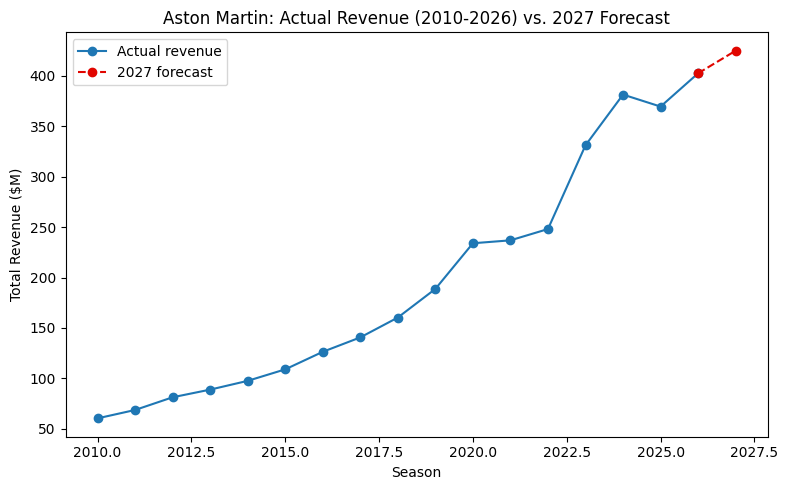

Aston Martin -- 2026 actual revenue: $402.6M
Aston Martin -- projected 2027 operating budget: $303.6M (+5.3% avg recent growth)
Aston Martin -- predicted 2027 revenue: $425.0M (+5.6% vs 2026)


In [11]:
team = "Aston Martin"
hist_team = df[df.team_name == team][["season", "operating_budget_usd_m", "total_revenue_usd_m"]]
pred_row = future[future.team_name == team].iloc[0]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(hist_team["season"], hist_team["total_revenue_usd_m"], marker="o", label="Actual revenue")
ax.plot([2026, 2027], [hist_team["total_revenue_usd_m"].iloc[-1], pred_row["predicted_total_revenue_usd_m"]],
        marker="o", linestyle="--", color="#e10600", label="2027 forecast")
ax.set_title(f"{team}: Actual Revenue (2010-2026) vs. 2027 Forecast")
ax.set_xlabel("Season")
ax.set_ylabel("Total Revenue ($M)")
ax.legend()
plt.tight_layout()
plt.savefig("aston_martin_forecast.png", dpi=150)
plt.show()

print(f"{team} -- 2026 actual revenue: ${hist_team['total_revenue_usd_m'].iloc[-1]:.1f}M")
print(f"{team} -- projected 2027 operating budget: ${pred_row['operating_budget_usd_m']:.1f}M "
      f"({recent_growth[team]*100:+.1f}% avg recent growth)")
print(f"{team} -- predicted 2027 revenue: ${pred_row['predicted_total_revenue_usd_m']:.1f}M "
      f"({pred_row['yoy_change_pct']:+.1f}% vs 2026)")

## 7. Conclusions

**Data source.** This notebook works from the team's shared `regression_dataset.csv` rather than re-deriving a merged dataset from the raw Kaggle tables, so it stays consistent with the preprocessing and feature-selection work already done upstream. The target, `total_revenue_usd_m`, was reconstructed by summing the file's `sponsorship_revenue_usd_m` and `prize_money_usd_m` columns — those two columns are never used as model *inputs*, only as the components the label is built from, so this does not reopen the leakage issue the preprocessing notebook flagged.

**Model choice.** Ridge regression on a lag-and-trend feature set outperformed an unregularized linear model and a random forest on time-based validation, and consistently beat a naive "same as last year" baseline across four rolling train/test windows (2023 through 2026 as the held-out season). The final model was refit on the complete 2011–2026 history (in-sample R² ≈ 0.98) before generating the 2027 forecast.

**What actually drives the forecast.** Prior-season revenue and the team's operating budget are by far the strongest predictors — revenue is highly persistent year over year, which is exactly what the naive-baseline comparison shows. Team identity contributes a real but secondary effect (brand-specific sponsorship premiums), and F1-wide commercial growth (broadcast/sponsorship trend) adds a small steady tailwind.

**2027 forecast.** Every team is projected to grow revenue modestly year over year, consistent with F1's overall commercial trajectory and each team's own budget trend. McLaren, Ferrari, Red Bull Racing, and Mercedes are projected to remain the top four earners, matching their 2026 ordering — the model does not predict any change in the competitive financial hierarchy for 2027, only continued growth within it.

**Limitations, stated plainly:**
- This is a projection conditioned on trend-based assumptions about 2027 budgets and F1-wide macro figures, not a guarantee — if a team's spending or the sport's commercial deals shift sharply from recent trend, the forecast will be off.
- With only 10 teams and 17 seasons (153 usable rows after creating lag features), the model has limited data to learn team-specific effects precisely; the coefficient estimates should be read directionally, not as precise dollar effects.
- The forecast assumes 2027 looks structurally like 2026 (same 10 teams, same cost-cap regime). A new team entry, team exit, or cost-cap rule change would invalidate it.
